# Variational Autoencoder (VAE) on MNIST



In [ ]:
# 2. Imports and environment check

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


In [ ]:
# Load MNIST
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


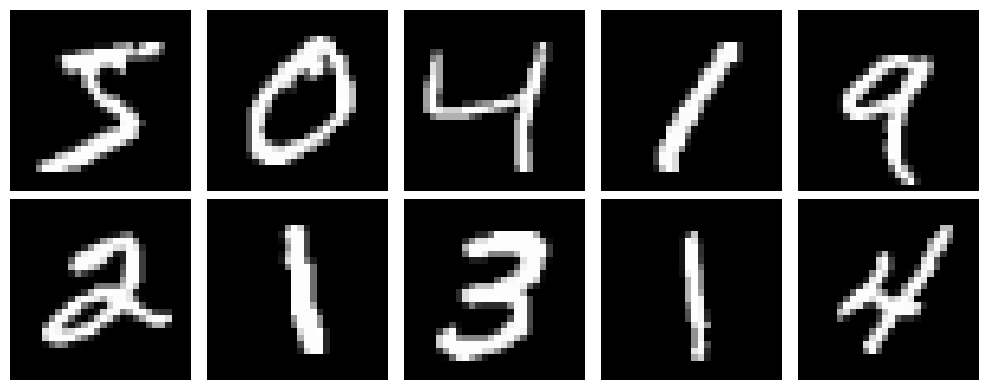

In [ ]:
# Display sample images

plt.figure(figsize=(10, 4))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
original_dim = 28 * 28
latent_dim = 2
batch_size = 128
epochs = 30

print("Original dimension:", original_dim)
print("Latent dimension:", latent_dim)


Original dimension: 784
Latent dimension: 2


In [ ]:
# Encoder

encoder_inputs = keras.Input(shape=(28, 28, 1), name="encoder_input")

x = layers.Flatten(name="flatten")(encoder_inputs)
x = layers.Dense(256, activation="relu", name="encoder_dense_1")(x)
x = layers.Dense(128, activation="relu", name="encoder_dense_2")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

encoder = keras.Model(
    encoder_inputs,
    [z_mean, z_log_var],
    name="encoder"
)

encoder.summary()


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 784)       │          0 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_1     │ (None, 256)       │    200,960 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_2     │ (None, 128)       │     32,896 │ encoder_dense_1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ encoder_dense_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ encoder_dense_2[… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 234,372 (915.52 KB)

 Trainable params: 234,372 (915.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Reparameterization function

def sample_latent(z_mean, z_log_var):
    epsilon = tf.random.normal(
        shape=tf.shape(z_mean),
        mean=0.0,
        stddev=1.0
    )
    sigma = tf.exp(0.5 * z_log_var)
    z = z_mean + sigma * epsilon
    return z


In [ ]:
# Decoder

latent_inputs = keras.Input(
    shape=(latent_dim,),
    name="decoder_input"
)

# Layer 1
x = layers.Dense(
    128,
    activation="relu",
    name="decoder_dense_1"
)(latent_inputs)

# Layer 2
x = layers.Dense(
    256,
    activation="relu",
    name="decoder_dense_2"
)(x)

# Layer 3
x = layers.Dense(
    28 * 28,
    activation="sigmoid",
    name="decoder_output_flat"
)(x)   # <-- IMPORTANT

# Convert 784 values back to 28 × 28 × 1
decoder_outputs = layers.Reshape(
    (28, 28, 1),
    name="decoder_output"
)(x)

# Create Decoder model
decoder = keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)

decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output_flat (Dense)     │ (None, 784)            │       201,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Reshape)        │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,896 (917.56 KB)

 Trainable params: 234,896 (917.56 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Complete VAE model

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var = self.encoder(data)
            z = sample_latent(z_mean, z_log_var)
            reconstruction = self.decoder(z)

            # Reconstruction loss
            bce = keras.losses.binary_crossentropy(
                data, reconstruction
            )
            reconstruction_loss = tf.reduce_sum(bce, axis=(1, 2))
            reconstruction_loss = tf.reduce_mean(reconstruction_loss)

            # KL divergence
            kl_loss = -0.5 * tf.reduce_sum(
                1 + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var),
                axis=1
            )
            kl_loss = tf.reduce_mean(kl_loss)

            total_loss = reconstruction_loss + kl_loss

        # Backpropagation
        grads = tape.gradient(total_loss, self.trainable_weights)

        # Weight update
        self.optimizer.apply_gradients(
            zip(grads, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def call(self, inputs):
        z_mean, z_log_var = self.encoder(inputs)
        z = sample_latent(z_mean, z_log_var)
        return self.decoder(z)


vae = VAE(encoder, decoder, name="vae")
vae.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3)
)

print("VAE created successfully.")


VAE created successfully.


In [ ]:
# Train

history = vae.fit(
    x_train,
    epochs=epochs,
    batch_size=batch_size
)


Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - kl_loss: 5.5862 - loss: 194.4740 - reconstruction_loss: 188.8879
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - kl_loss: 5.0045 - loss: 166.7253 - reconstruction_loss: 161.7208
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - kl_loss: 5.4577 - loss: 159.3817 - reconstruction_loss: 153.9240
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - kl_loss: 5.6231 - loss: 155.7768 - reconstruction_loss: 150.1536
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - kl_loss: 5.7342 - loss: 153.6693 - reconstruction_loss: 147.9351
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - kl_loss: 5.8026 - loss: 152.2019 - reconstruction_loss: 146.3992
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - kl_loss: 5.8654 - loss: 151.0110 - reconstruction_loss: 145.1456
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - kl_loss: 5.9089 - loss: 149.9419 - reconstruction_loss: 144.0330
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━

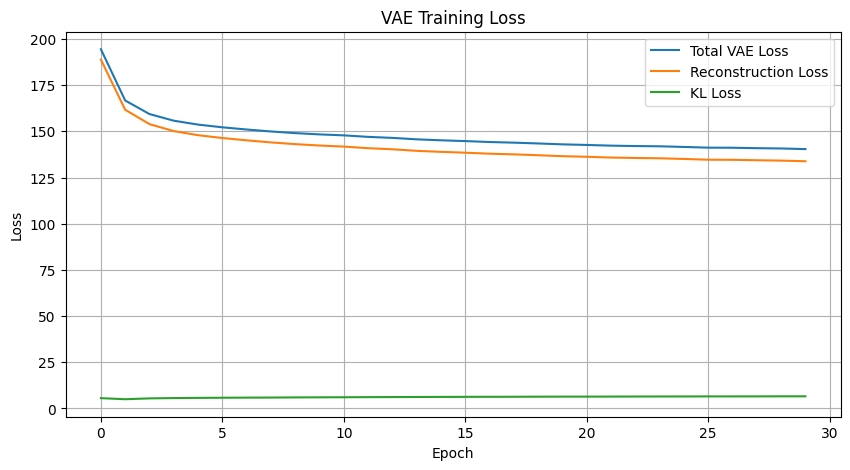

In [ ]:
# Plot training losses

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Total VAE Loss")
plt.plot(history.history["reconstruction_loss"], label="Reconstruction Loss")
plt.plot(history.history["kl_loss"], label="KL Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True)
plt.show()


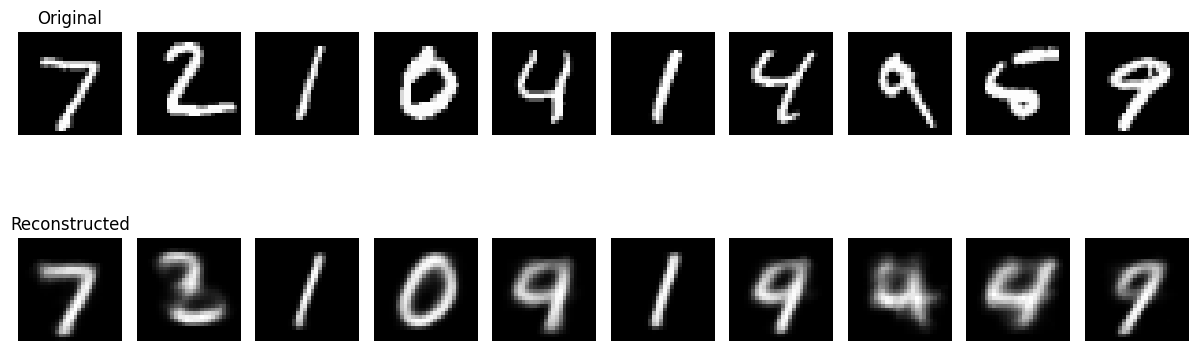

In [ ]:
# Reconstruct test images

z_mean_test, z_log_var_test = encoder.predict(
    x_test[:10], verbose=0
)

z_test = sample_latent(
    z_mean_test, z_log_var_test
)

reconstructed = decoder.predict(
    z_test, verbose=0
)

plt.figure(figsize=(12, 5))

for i in range(10):
    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        ax.set_title("Original")

    ax = plt.subplot(2, 10, 10 + i + 1)
    plt.imshow(reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        ax.set_title("Reconstructed")

plt.tight_layout()
plt.show()


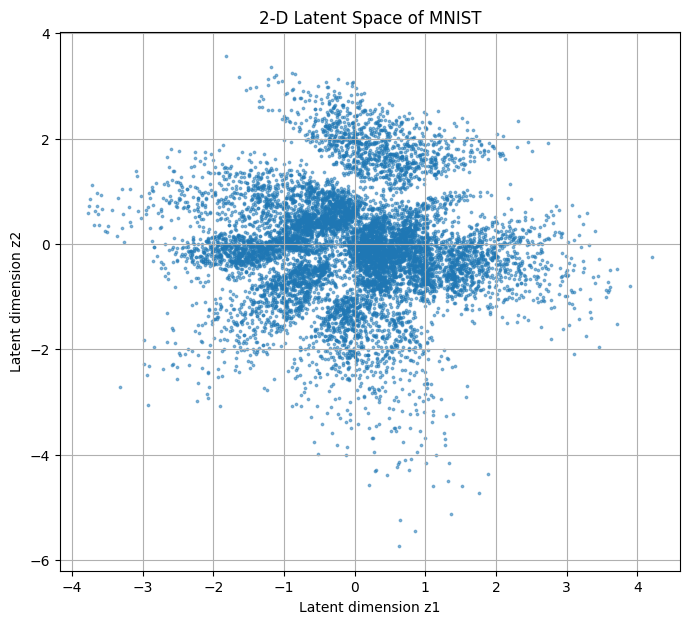

In [ ]:
# Plot latent means

z_mean_all, z_log_var_all = encoder.predict(
    x_test, verbose=0
)

plt.figure(figsize=(8, 7))
plt.scatter(
    z_mean_all[:, 0],
    z_mean_all[:, 1],
    s=3,
    alpha=0.5
)
plt.xlabel("Latent dimension z1")
plt.ylabel("Latent dimension z2")
plt.title("2-D Latent Space of MNIST")
plt.grid(True)
plt.show()


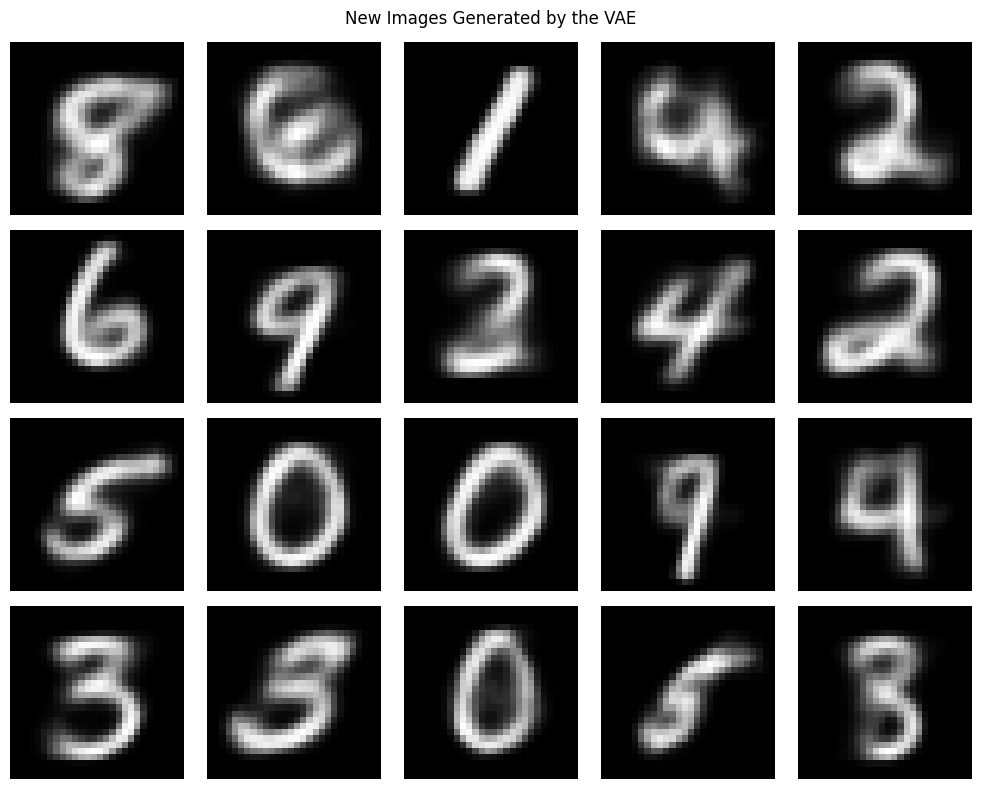

In [ ]:
# Generate 20 new images

num_images = 20

random_z = tf.random.normal(
    shape=(num_images, latent_dim)
)

generated_images = decoder.predict(
    random_z,
    verbose=0
)

plt.figure(figsize=(10, 8))

for i in range(num_images):
    plt.subplot(4, 5, i + 1)
    plt.imshow(generated_images[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("New Images Generated by the VAE")
plt.tight_layout()
plt.show()


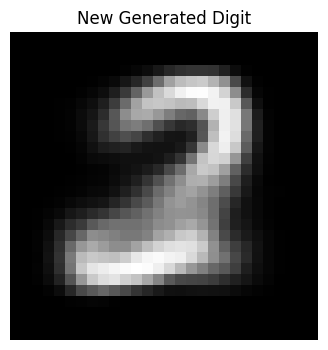

In [ ]:
# Generate one image

z = tf.random.normal(shape=(1, latent_dim))

new_image = decoder.predict(
    z,
    verbose=0
)[0]

plt.figure(figsize=(4, 4))
plt.imshow(new_image.squeeze(), cmap="gray")
plt.axis("off")
plt.title("New Generated Digit")
plt.show()


In [ ]:
# Save Encoder and Decoder

SAVE_DIR = "/content/vae_mnist_models"
os.makedirs(SAVE_DIR, exist_ok=True)

encoder_path = os.path.join(
    SAVE_DIR,
    "vae_encoder.keras"
)

decoder_path = os.path.join(
    SAVE_DIR,
    "vae_decoder.keras"
)

# Make sure the models are built before saving
_ = encoder(x_train[:1])
_ = decoder(tf.zeros((1, latent_dim)))

# Save Functional Keras models
encoder.save(encoder_path)
decoder.save(decoder_path)

print("Models saved successfully!")
print()
print("Encoder :", encoder_path)
print("Decoder :", decoder_path)

Models saved successfully!

Encoder : /content/vae_mnist_models/vae_encoder.keras
Decoder : /content/vae_mnist_models/vae_decoder.keras


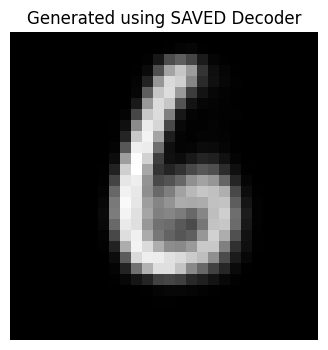

In [ ]:
# Load saved decoder and generate a test image

loaded_decoder = keras.models.load_model(
    decoder_path
)

test_z = tf.random.normal(shape=(1, latent_dim))

test_image = loaded_decoder.predict(
    test_z,
    verbose=0
)[0]

plt.figure(figsize=(4, 4))
plt.imshow(test_image.squeeze(), cmap="gray")
plt.axis("off")
plt.title("Generated using SAVED Decoder")
plt.show()


In [ ]:
# Create ZIP archive

import shutil

zip_path = shutil.make_archive(
    "/content/vae_mnist_models",
    "zip",
    SAVE_DIR
)

print("ZIP created:", zip_path)


ZIP created: /content/vae_mnist_models.zip


In [ ]:
# Download ZIP to your computer

from google.colab import files

files.download("/content/vae_mnist_models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
<!DOCTYPE html>

<html lang="en">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>VAE MNIST Digit Generator</title>

    <link rel="stylesheet"
          href="{{ url_for('static', filename='style.css') }}">

</head>


<body>


<div class="container">


    <div class="card">


        <h1>VAE Digit Generator</h1>


        <p class="subtitle">

            Select a number and generate a new
            MNIST-style handwritten image using the
            trained VAE Decoder.

        </p>


        <!-- Digit Selection -->

        <div class="section">

            <h2>Select a Digit</h2>


            <div class="digit-grid">

                <button class="digit-btn active" data-digit="0">
                    0
                </button>

                <button class="digit-btn" data-digit="1">
                    1
                </button>

                <button class="digit-btn" data-digit="2">
                    2
                </button>

                <button class="digit-btn" data-digit="3">
                    3
                </button>

                <button class="digit-btn" data-digit="4">
                    4
                </button>

                <button class="digit-btn" data-digit="5">
                    5
                </button>

                <button class="digit-btn" data-digit="6">
                    6
                </button>

                <button class="digit-btn" data-digit="7">
                    7
                </button>

                <button class="digit-btn" data-digit="8">
                    8
                </button>

                <button class="digit-btn" data-digit="9">
                    9
                </button>

            </div>

        </div>


        <!-- Selected Digit -->

        <div class="selected-info">

            Selected Number:

            <span id="selectedDigit">
                0
            </span>

        </div>


        <!-- Generate Button -->

        <button id="generateBtn">

            Generate Image

        </button>


        <!-- Loading -->

        <div id="loading"
             class="loading hidden">

            Generating image...

        </div>


        <!-- Generated Image -->

        <div class="image-section">


            <h2>Generated Image</h2>


            <div class="image-box">


                <img
                    id="generatedImage"
                    src=""
                    alt="Generated digit"
                >


                <p id="placeholder">

                    Your generated image will appear here

                </p>


            </div>


        </div>


    </div>


</div>



<script>


let selectedDigit = 0;


const digitButtons =
    document.querySelectorAll(".digit-btn");


const selectedDigitText =
    document.getElementById("selectedDigit");


const generateBtn =
    document.getElementById("generateBtn");


const generatedImage =
    document.getElementById("generatedImage");


const placeholder =
    document.getElementById("placeholder");


const loading =
    document.getElementById("loading");



/* ------------------------------------------
   Select Digit
------------------------------------------ */

digitButtons.forEach(function(button) {

    button.addEventListener("click", function() {


        // Remove active class
        digitButtons.forEach(function(btn) {

            btn.classList.remove("active");

        });


        // Add active class
        this.classList.add("active");


        // Store selected digit
        selectedDigit =
            parseInt(this.dataset.digit);


        // Display selected digit
        selectedDigitText.textContent =
            selectedDigit;

    });

});



/* ------------------------------------------
   Generate Image
------------------------------------------ */

generateBtn.addEventListener(
    "click",
    async function() {


        loading.classList.remove("hidden");


        generateBtn.disabled = true;


        try {


            const response =
                await fetch("/generate", {

                    method: "POST",

                    headers: {

                        "Content-Type":
                            "application/json"

                    },

                    body: JSON.stringify({

                        digit: selectedDigit

                    })

                });


            const data =
                await response.json();


            if (data.success) {


                generatedImage.src =
                    "data:image/png;base64,"
                    + data.image;


                generatedImage.style.display =
                    "block";


                placeholder.style.display =
                    "none";


            }

            else {

                alert(
                    "Error: "
                    + data.error
                );

            }


        }

        catch (error) {

            alert(
                "Something went wrong: "
                + error
            );

        }


        finally {


            loading.classList.add(
                "hidden"
            );


            generateBtn.disabled =
                false;


        }


    }
);


</script>


</body>

</html>

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 122)

In [ ]:
from flask import Flask, render_template, request, jsonify
import tensorflow as tf
import numpy as np
import base64
import io

from PIL import Image


app = Flask(__name__)


# --------------------------------------------------
# Load the trained VAE Decoder
# --------------------------------------------------

MODEL_PATH = "models/vae_decoder.keras"

decoder = tf.keras.models.load_model(MODEL_PATH)

print("VAE Decoder loaded successfully!")
print("Decoder input shape:", decoder.input_shape)
print("Decoder output shape:", decoder.output_shape)


# --------------------------------------------------
# Home Page
# --------------------------------------------------

@app.route("/")
def home():
    return render_template("index.html")


# --------------------------------------------------
# Generate Image
# --------------------------------------------------

@app.route("/generate", methods=["POST"])
def generate():

    try:

        # Get selected digit from UI
        data = request.get_json()

        selected_digit = int(data.get("digit", 0))

        # Validate digit
        if selected_digit < 0 or selected_digit > 9:
            return jsonify({
                "success": False,
                "error": "Please select a number between 0 and 9."
            }), 400


        # --------------------------------------------------
        # Generate random latent vector
        #
        # Your VAE was trained with latent_dim = 2
        # --------------------------------------------------

        latent_dim = 2

        z = tf.random.normal(
            shape=(1, latent_dim),
            mean=0.0,
            stddev=1.0
        )


        # --------------------------------------------------
        # Generate image using decoder
        # --------------------------------------------------

        generated_image = decoder.predict(
            z,
            verbose=0
        )[0]


        # Remove channel dimension
        generated_image = generated_image.squeeze()


        # Convert values from 0-1 to 0-255
        generated_image = (
            generated_image * 255
        ).astype(np.uint8)


        # --------------------------------------------------
        # Convert image to PNG
        # --------------------------------------------------

        image = Image.fromarray(
            generated_image,
            mode="L"
        )

        buffer = io.BytesIO()

        image.save(
            buffer,
            format="PNG"
        )

        buffer.seek(0)


        # Convert image to Base64
        image_base64 = base64.b64encode(
            buffer.getvalue()
        ).decode("utf-8")


        return jsonify({
            "success": True,
            "selected_digit": selected_digit,
            "image": image_base64
        })


    except Exception as e:

        print("ERROR:", str(e))

        return jsonify({
            "success": False,
            "error": str(e)
        }), 500


# --------------------------------------------------
# Run Flask Application
# --------------------------------------------------

if __name__ == "__main__":

    app.run(
        debug=True,
        host="127.0.0.1",
        port=5000
    )

In [ ]:
import pickle

# Save decoder model using pickle
with open("vae_decoder.pkl", "wb") as file:
    pickle.dump(decoder, file)

print("Decoder model saved successfully as vae_decoder.pkl")